# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de cinco camadas ocultas
---

***A Fazeres:***
- Buscar `GridSearch`
- Buscar `Ensamble`
- Buscar `LaTeX`
- Buscar `overleaf.com`

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `MLP` de duas camadas. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Os modelos de três e cinco camadas ocultas são consideravelmente mais pesados e difíceis de treinar do que o de duas. Foi apontado que este, por meio do `GridSearchCV`, que a melhor arquitetura é de **funil decrescente**. Portanto, para os modelos com mais camadas, será treinado apenas o modelo com `RFE` e a arquitura mencionada.

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')

# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento do Modelo de MLPde Classificação de cincos camadas com 20 features (RFE + XGBoost Classifier)
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 20 features mais relevantes.

In [8]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [9]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=20)

#### 1.2. Aplicação do RFE em X_treino
---

In [10]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [11]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features: {X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [12]:
type(X_treino_reduzido)

numpy.ndarray

In [13]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.329992,-0.154433,-0.034939,-0.002418,-0.4,-0.333333,-0.054359,1.0,-0.009828,-0.016261,-0.004038,-0.547945,-0.274074,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.131161,12.130358,-0.044014,0.808271,0.0,2.500000,0.269346,1.0,-0.009828,-0.016261,-0.004038,-0.424658,7.600000,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.285714,3.666471,-0.054756,0.083443,-0.2,0.666667,2.568450,1.0,0.845333,0.898078,0.820533,-0.506849,5.511111,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.175439,0.021139,-0.052917,-0.010829,-0.2,0.166667,1.570283,1.0,-0.009828,-0.016261,-0.004038,-0.424658,-0.118519,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.214703,-0.126248,-0.043752,-0.009800,0.0,-0.166667,0.241995,1.0,0.971310,1.042226,0.931617,-0.410959,-0.259259,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [14]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 1065.6872198364367

 - Magnitude: 1066.0485584896207


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 19.24055182089483

 - Magnitu

#### 1.3. Aplicação do RFE em X_teste
---

In [15]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [16]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [17]:
type(X_teste_reduzido)

numpy.ndarray

In [18]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.230576,-0.204932,283.916144,-0.016329,-0.4,-0.333333,-0.361200,0.0,-0.009828,-0.016261,-0.004038,2.260274,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.298246,-0.204932,1387.032509,-0.016329,-0.4,-0.333333,-0.361238,0.0,-0.009828,-0.016261,-0.004038,10.931507,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,0.008354,-0.204932,1345.152161,-0.016329,-0.4,-0.333333,-0.361275,0.0,-0.009828,-0.016261,-0.004038,6.178082,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,-0.061821,-0.204932,944.612285,-0.016329,-0.4,-0.333333,-0.361263,0.0,-0.009828,-0.016261,-0.004038,5.027397,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,0.450292,-0.204932,1338.854364,-0.016329,-0.4,-0.333333,-0.361212,0.0,-0.009828,-0.016261,-0.004038,13.424658,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0


In [19]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 757.8754070510212

 - Magnitude: 758.2367457042053


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 29.195324055790017

 

### 2. Instanciação classe MLPClassifier
---

In [20]:

mlp_rfe = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128, 64, 32),
    max_iter=2000, 
    tol=0.0001,
    learning_rate_init=0.001, 
    learning_rate='adaptive', 
    alpha=0.001, 
    n_iter_no_change=15, 
    solver="adam", 
    activation='relu', 
    random_state=42,
    verbose=True
)

### 3. Treino do modelo
---

In [21]:
pm.imprimir_desempenho(mlp_rfe.fit, X_treino_reduzido_df, y_treino)

Iteration 1, loss = 0.33298065
Iteration 2, loss = 0.23158125
Iteration 3, loss = 0.21345499
Iteration 4, loss = 0.20939931
Iteration 5, loss = 0.20429363
Iteration 6, loss = 0.19824443
Iteration 7, loss = 0.19912439
Iteration 8, loss = 0.19632306
Iteration 9, loss = 0.19392863
Iteration 10, loss = 0.19344433
Iteration 11, loss = 0.20669749
Iteration 12, loss = 0.19258821
Iteration 13, loss = 0.19045017
Iteration 14, loss = 0.18761977
Iteration 15, loss = 0.19123824
Iteration 16, loss = 0.18760455
Iteration 17, loss = 0.18676641
Iteration 18, loss = 0.18789919
Iteration 19, loss = 0.18272144
Iteration 20, loss = 0.18374566
Iteration 21, loss = 0.17846910
Iteration 22, loss = 0.17820911
Iteration 23, loss = 0.17766672
Iteration 24, loss = 0.17557433
Iteration 25, loss = 0.17389638
Iteration 26, loss = 0.17338147
Iteration 27, loss = 0.18089078
Iteration 28, loss = 0.17938231
Iteration 29, loss = 0.17739069
Iteration 30, loss = 0.17559432
Iteration 31, loss = 0.17732149
Iteration 32, los

MLPClassifier(alpha=0.001, hidden_layer_sizes=(512, 256, 128, 64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 4. Realização das Predições de Teste
---

#### 4.1. Predição Probababilística
---

In [22]:
y_predicao_probabilistica = pm.imprimir_desempenho(mlp_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 08:44:20

    1. TEMPO: 10.8270s (0.18 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 292.80 MB
        - Diferença líquida de RAM no processo: 50.90 MB
        - Total RAM alocada para o processo: 443.32 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 74.2%

  Execução concluída em: 30/05/2026 08:44:31



#### 4.2. Predição Binária
---

In [23]:
y_predicao_binaria = pm.imprimir_desempenho(mlp_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 08:44:31

    1. TEMPO: 10.4220s (0.17 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 292.80 MB
        - Diferença líquida de RAM no processo: -1.63 MB
        - Total RAM alocada para o processo: 441.69 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 72.9%

  Execução concluída em: 30/05/2026 08:44:41



### 5. Desempenho do modelo
---

#### 5.1. Limiar Padrão (0.5)
---

##### 5.1.1. Matriz de Confusão
---

<Axes: >

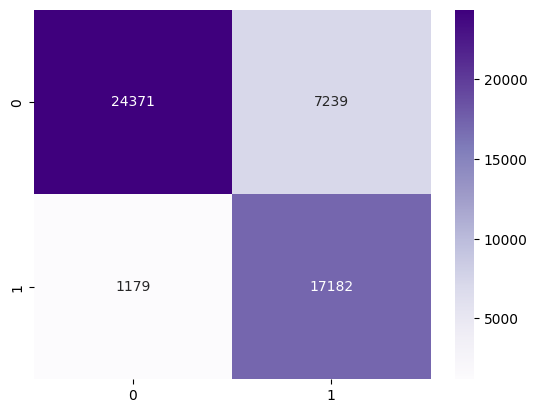

In [24]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Purples')

##### 5.1.2. Relatório de Classificação
---

In [25]:
relatorio_classificacao= classification_report(y_teste, y_predicao_binaria)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.95      0.77      0.85     31610
         1.0       0.70      0.94      0.80     18361

    accuracy                           0.83     49971
   macro avg       0.83      0.85      0.83     49971
weighted avg       0.86      0.83      0.83     49971



##### 5.1.3. Curva ROC-AUC
---

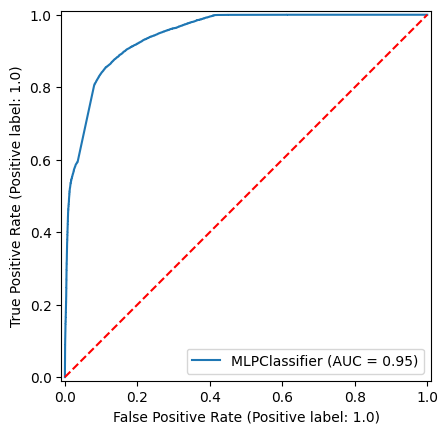

In [26]:
pg.gerar_roc_auc(mlp_rfe, X_teste_reduzido_df, y_teste)

##### 5.1.4. Curva Precision-Recall
---

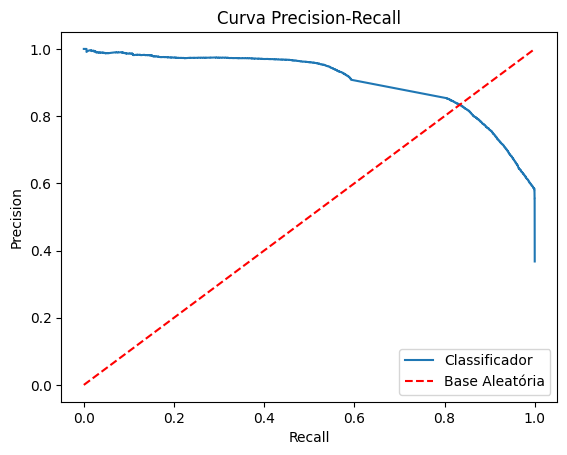

In [27]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica)

In [28]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4597
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 67.70% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9430
      Recall real obtido: 53.72% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7775
      Recall neste ponto: 84.10% (Ataques detectados)
      Precision neste ponto: 82.82% (Acerto dos alertas)


##### 5.1.5. Curva de Aprendizado
---

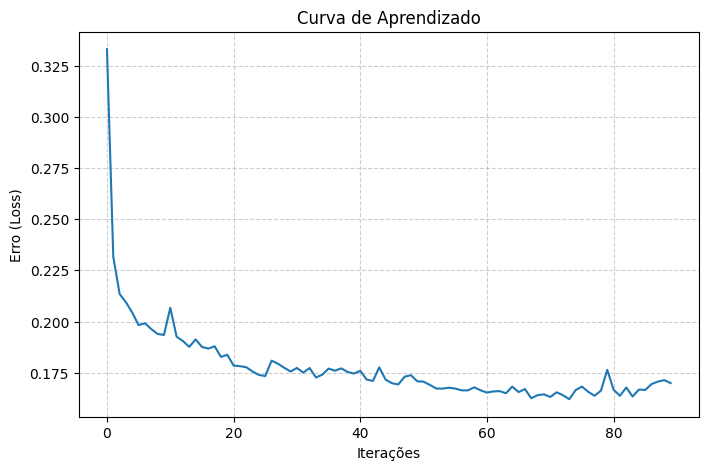

In [29]:
pg.gerar_curva_aprendizado(mlp_rfe)

#### 5.2. Limiar Equilibrado
---

##### 5.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [30]:
_, limiar_mlp_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica)
print(limiar_mlp_rfe)

0.7775496831830606


In [31]:
y_predicao_probabilistica_equilibrada = (y_predicao_probabilistica > limiar_mlp_rfe).astype(int)

<Axes: >

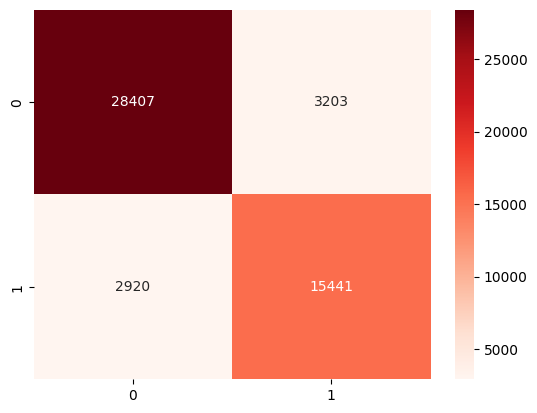

In [32]:
matriz_confusao_equilibrada = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada)
sns.heatmap(matriz_confusao_equilibrada, annot=True, fmt='d', cmap='Reds')

##### 5.2.2. Relatório de Classificação
---

In [33]:
relatorio_classificacao_equilibrado = classification_report(y_teste, y_predicao_probabilistica_equilibrada)
print(relatorio_classificacao_equilibrado)

              precision    recall  f1-score   support

         0.0       0.91      0.90      0.90     31610
         1.0       0.83      0.84      0.83     18361

    accuracy                           0.88     49971
   macro avg       0.87      0.87      0.87     49971
weighted avg       0.88      0.88      0.88     49971



## E) Comparando os Limiares
---

#### 1. Dados de Desempenho Modelo
---

In [34]:
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada)



 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 24371 casos, o que representa, aproximadamente, 48.77% do total de predições de teste.
    - Falso Negativo (FN): há 1179 casos, o que representa, aproximadamente, 2.36% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 17182 casos, o que representa, aproximadamente, 34.38% do total de predições de teste.
   - Falso Positivo (FP): há 7239 casos, o que representa, aproximadamente, 14.49% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.8315.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 41553, de um total de 49971. Corresponde a, aproximadamente, 83.15% das predições.
    - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a 8418, de um total de 49971. Corresponde a, aproximadamente, 16.85% das predições.


 

#### 2. Diferenças entre os desempenhos
---

In [36]:
dados_modelo = pm.extracao_desempenho_modelo(matriz_confusao)
dados_modelo_equilibrado = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada)

# Total de registros
total_registros = dados_modelo['tn'] + dados_modelo['tp'] + dados_modelo['fn'] + dados_modelo['fp']

In [38]:
print('As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo["tn"]} | Equilibrado - {dados_modelo_equilibrado["tn"]} -> Diferença de {dados_modelo["tn"] - dados_modelo_equilibrado["tn"]} ou {pm.calcular_percentual((dados_modelo["tn"] - dados_modelo_equilibrado["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo["tp"]} | Equilibrado - {dados_modelo_equilibrado["tp"]} -> Diferença de {dados_modelo["tp"] - dados_modelo_equilibrado["tp"]} ou {pm.calcular_percentual((dados_modelo["tp"] - dados_modelo_equilibrado["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo["fn"]} | Equilibrado - {dados_modelo_equilibrado["fn"]} -> Diferença de {dados_modelo["fn"] - dados_modelo_equilibrado["fn"]} ou {pm.calcular_percentual((dados_modelo["fn"] - dados_modelo_equilibrado["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo["fp"]} | Equilibrado - {dados_modelo_equilibrado["fp"]} -> Diferença de {dados_modelo["fp"] - dados_modelo_equilibrado["fp"]} ou {pm.calcular_percentual((dados_modelo["fp"] - dados_modelo_equilibrado["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo["accuracy"]} | Equilibrado - {dados_modelo_equilibrado["accuracy"]} -> Diferença de {round(dados_modelo["accuracy"] - dados_modelo_equilibrado["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo["accuracy"] - dados_modelo_equilibrado["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Padrão - {dados_modelo["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado["classe_0"]["recall"]} -> Diferença de {round(dados_modelo["classe_0"]["recall"] - dados_modelo_equilibrado["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_0"]["recall"] - dados_modelo_equilibrado["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado["classe_0"]["precision"]} -> Diferença de {round(dados_modelo["classe_0"]["precision"] - dados_modelo_equilibrado["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_0"]["precision"] - dados_modelo_equilibrado["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo["classe_0"]["f1_score"] - dados_modelo_equilibrado["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_0"]["f1_score"] - dados_modelo_equilibrado["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Padrão - {dados_modelo["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado["classe_1"]["recall"]} -> Diferença de {round(dados_modelo["classe_1"]["recall"] - dados_modelo_equilibrado["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_1"]["recall"] - dados_modelo_equilibrado["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado["classe_1"]["precision"]} -> Diferença de {round(dados_modelo["classe_1"]["precision"] - dados_modelo_equilibrado["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_1"]["precision"] - dados_modelo_equilibrado["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo["classe_1"]["f1_score"] - dados_modelo_equilibrado["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo["classe_1"]["f1_score"] - dados_modelo_equilibrado["classe_1"]["f1_score"], 1):.2f}%')

As diferenças métricas entre os modelos são:

Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).

 - Métricas Básicas:
    TN: Padrão - 24371 | Equilibrado - 28407 -> Diferença de -4036 ou -8.08%
    TP: Padrão - 17182 | Equilibrado - 15441 -> Diferença de 1741 ou 3.48%
    FN: Padrão - 1179 | Equilibrado - 2920 -> Diferença de -1741 ou -3.48%
    FP: Padrão - 7239 | Equilibrado - 3203 -> Diferença de 4036 ou 8.08%

 - Acurácia Geral do Modelo:
    Acurácia: Padrão - 0.8315 | Equilibrado - 0.8775 -> Diferença de -0.046 ou -4.60%

 - Classe 0:
    Recall: Padrão - 0.771 | Equilibrado - 0.8987 -> Diferença de -0.1277 ou -12.77%
    Precision: Padrão - 0.9539 | Equilibrado - 0.9068 -> Diferença de 0.0471 ou 4.71%
    F1-Score: Padrão - 0.8527 | Equilibrado - 0.9027 -> Diferença de -0.05 ou -5.00%

 - Classe 1:
    Recall: Padrão - 0.

## F) Persisitindo o Modelo
---

In [ ]:
joblib.dump(mlp_rfe, '../persistencia/modelos_persistentes/mlp/mlp_5c/mlp_5c_rfe.pkl')